# 13 Grad-CAM Explainability & Visualization

## Objective
Generate Gradient-weighted Class Activation Mapping (Grad-CAM) visual explanations to interpret model predictions and verify diseased region localization on leaf surfaces.

**Prerequisites:** Trained models from notebooks 05, 06, 09, 10 and test dataset

### Import Libraries

In [1]:
import sys
import os
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / 'utils'))

from model_utils import load_model

import numpy as np
import tensorflow as tf
import json
import cv2
import matplotlib.pyplot as plt
import matplotlib.cm as cm

print("✓ Libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")


✓ Libraries imported successfully!
TensorFlow version: 2.15.0


### Load Data and Model

In [2]:
print("Loading test data and model...\n")

project_root = Path.cwd().resolve()
if not (project_root / "results").exists():
    project_root = project_root.parent

base_path = project_root / "results" / "preprocessed_data_efficient"
legacy_path = project_root / "results" / "preprocessed_data"

if base_path.exists() and (base_path / "test_images").exists():
    from npz_consolidator import load_consolidated_arrays
    X_test = load_consolidated_arrays(str(base_path), split_type="test")
    with open(base_path / "image_metadata.json", "r") as f:
        metadata = json.load(f)
    with open(base_path / "split_indices.json", "r") as f:
        split_info = json.load(f)
    with open(base_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)
    labels_all = np.array(metadata["labels"])
    test_indices = split_info["test_indices"]
    y_test = tf.keras.utils.to_categorical(labels_all[test_indices], num_classes=len(label_encoding)).astype(np.float32)
    print(f"✓ Loaded test data from: {base_path}")
elif legacy_path.exists():
    X_test = np.load(str(legacy_path / "X_test.npy"))
    y_test = np.load(str(legacy_path / "y_test.npy"))
    with open(legacy_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)
    print("✓ Loaded test data from legacy folder")
else:
    raise FileNotFoundError(f"No test data found in {base_path} or {legacy_path}")

num_classes = len(label_encoding)
reverse_encoding = {v: k for k, v in label_encoding.items()}
class_names = [reverse_encoding[i] for i in range(num_classes)]

import pandas as pd

comparison_csv = project_root / "results" / "reports" / "model_comparison.csv"
model = None
best_model_name = None
model_path = None

if comparison_csv.exists():
    comparison_df = pd.read_csv(comparison_csv)
    if not comparison_df.empty and {"Model", "Accuracy", "Path"}.issubset(comparison_df.columns):
        best_row = comparison_df.sort_values("Accuracy", ascending=False).iloc[0]
        candidate_path = Path(best_row["Path"])
        if candidate_path.exists():
            model = load_model(str(candidate_path))
            best_model_name = str(best_row["Model"])
            model_path = str(candidate_path)
            print(f"✓ Loaded best model from notebook 11 comparison: {best_model_name}")
            print(f"  Path: {candidate_path}")
        else:
            print(f"⚠️ Best model path from comparison report does not exist: {candidate_path}")
    else:
        print("⚠️ model_comparison.csv is missing expected columns; falling back to a direct model search.")
else:
    print("⚠️ model_comparison.csv not found; falling back to a direct model search.")

if model is None:
    model_paths_to_try = [
        project_root / "models" / "resnet50" / "resnet50_final.h5",
        project_root / "models" / "efficientnetb0" / "efficientnetb0_final.h5",
        project_root / "models" / "mobilenet" / "mobilenet_v2_final.h5",
    ]

    for mp in model_paths_to_try:
        if mp.exists():
            model = load_model(str(mp))
            best_model_name = mp.parent.name
            model_path = str(mp)
            break

if model is None:
    raise FileNotFoundError("Could not find any trained model file")

input_shape = getattr(model, 'input_shape', None)
if input_shape is not None and len(input_shape) >= 4:
    target_height, target_width = input_shape[1], input_shape[2]
    if X_test.shape[1:3] != (target_height, target_width):
        X_test = tf.image.resize(X_test, (target_height, target_width), method=tf.image.ResizeMethod.BILINEAR).numpy()
        print(f"✓ Resized X_test to {target_height}x{target_width}")
    # All trained models expect inputs in range [0, 1]
    if np.max(X_test) > 1.0:
        X_test = X_test / 255.0
        print("✓ Scaled X_test pixel values to [0, 1]")
    else:
        print("✓ Kept X_test pixel values in [0, 1]")

print(f"✓ Model loaded: {best_model_name}")
print(f"✓ Test data shape: {X_test.shape}")


Loading test data and model...

Loading 860 images from test set...
  Loaded 100/860 images...
  Loaded 200/860 images...
  Loaded 300/860 images...
  Loaded 400/860 images...
  Loaded 500/860 images...
  Loaded 600/860 images...
  Loaded 700/860 images...
  Loaded 800/860 images...
✓ Consolidated test set: (860, 224, 224, 3), dtype: float32

✓ Loaded test data from: D:\cnn_model\results\preprocessed_data_efficient


✓ Loaded best model from notebook 11 comparison: ResNet50
  Path: D:\cnn_model\models\resnet50\resnet50_final.h5
✓ Kept X_test pixel values in [0, 1]
✓ Model loaded: ResNet50
✓ Test data shape: (860, 224, 224, 3)


### 1. Implement Grad-CAM

In [3]:
class GradCAM:
    """Grad-CAM implementation for model interpretability."""

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.containing_model = self._find_containing_model(model, target_layer)
        
        # Determine if target layer is in the top-level model or nested
        if self.containing_model == model:
            self.pre_layers = []
            self.backbone_model = tf.keras.models.Model(
                inputs=model.input,
                outputs=[self.target_layer.output, model.output]
            )
            self.post_layers = []
        else:
            # Find the top-level direct child layer that contains target_layer
            containing_child = None
            containing_child_idx = None
            for idx, layer in enumerate(model.layers):
                if layer == target_layer or (isinstance(layer, tf.keras.Model) and (layer == self.containing_model or self._is_descendant(layer, target_layer))):
                    containing_child = layer
                    containing_child_idx = idx
                    break
            
            if containing_child is None:
                raise ValueError(f"Could not find top-level child containing layer {target_layer.name}")
                
            self.pre_layers = model.layers[:containing_child_idx]
            self.backbone_model = tf.keras.models.Model(
                inputs=containing_child.input,
                outputs=[self.target_layer.output, containing_child.output]
            )
            self.post_layers = model.layers[containing_child_idx + 1:]

    @staticmethod
    def _is_descendant(parent, target):
        if not isinstance(parent, tf.keras.Model):
            return False
        if target in parent.layers:
            return True
        for layer in parent.layers:
            if isinstance(layer, tf.keras.Model):
                if GradCAM._is_descendant(layer, target):
                    return True
        return False

    @staticmethod
    def _find_containing_model(model, target_layer):
        if target_layer in model.layers:
            return model
        for layer in model.layers:
            if isinstance(layer, tf.keras.Model):
                try:
                    return GradCAM._find_containing_model(layer, target_layer)
                except ValueError:
                    continue
        raise ValueError(f"Layer {target_layer.name} not found in any nested model")

    def generate(self, img_array, pred_index=None):
        """Generate Grad-CAM heatmap."""
        with tf.GradientTape() as tape:
            # Forward pass through pre-backbone layers
            x = img_array
            for layer in self.pre_layers:
                x = layer(x)
                
            # Forward pass through the backbone model
            conv_outputs, backbone_output = self.backbone_model(x)
            tape.watch(conv_outputs)

            # Forward pass through post-backbone layers
            x = backbone_output
            for layer in self.post_layers:
                x = layer(x)
            predictions = x

            if pred_index is None:
                pred_index = int(tf.argmax(predictions[0]).numpy())
            class_channel = predictions[:, pred_index]

        grads = tape.gradient(class_channel, conv_outputs)
        if grads is None:
            raise ValueError('Gradients are None: check model connectivity and target layer selection.')

        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        conv_outputs = conv_outputs[0]
        heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0)
        max_val = tf.math.reduce_max(heatmap)
        if max_val == 0:
            return heatmap.numpy()
        return (heatmap / max_val).numpy()

    def overlay_heatmap(self, img, heatmap, alpha=0.4):
        """Overlay heatmap on original image."""
        heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
        heatmap_color = cm.jet(heatmap_resized)
        heatmap_rgb = (heatmap_color[:, :, :3] * 255).astype(np.uint8)
        return cv2.addWeighted(img.astype(np.uint8), 1 - alpha, heatmap_rgb, alpha, 0)


def find_last_conv_layer(keras_model):
    for layer in reversed(keras_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer
        if isinstance(layer, tf.keras.Model):
            nested = find_last_conv_layer(layer)
            if nested:
                return nested
    return None

last_conv_layer = find_last_conv_layer(model)
if last_conv_layer is None:
    candidate_layers = [l for l in reversed(model.layers) if 'conv' in l.name.lower()]
    last_conv_layer = candidate_layers[0] if candidate_layers else None

print(f"Model input shape: {model.input_shape}")
print("Available layers in top-level model:")
for layer in model.layers:
    print(f"  {layer.name} ({layer.__class__.__name__})")
print("Searching nested model layers for convolutional blocks...")
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        print(f"Nested model: {layer.name}")
        for nested_layer in layer.layers[-20:]:
            print(f"  {nested_layer.name} ({nested_layer.__class__.__name__})")

if last_conv_layer is not None:
    print(f"Selected conv layer: {last_conv_layer.name} ({type(last_conv_layer).__name__})")
else:
    print("No convolutional layer selected.")

if last_conv_layer is None:
    raise ValueError('No convolutional layer found for Grad-CAM. Check the model architecture.')

grad_cam = GradCAM(model, last_conv_layer)
print(f"✓ Grad-CAM initialized using layer {last_conv_layer.name}")



Model input shape: (None, 224, 224, 3)
Available layers in top-level model:
  resnet50_preprocessing (Rescaling)
  resnet50 (Functional)
  global_average_pooling2d_1 (GlobalAveragePooling2D)
  dense_2 (Dense)
  batch_normalization_1 (BatchNormalization)
  dropout_1 (Dropout)
  dense_3 (Dense)
Searching nested model layers for convolutional blocks...
Nested model: resnet50
  conv5_block2_1_conv (Conv2D)
  conv5_block2_1_bn (BatchNormalization)
  conv5_block2_1_relu (Activation)
  conv5_block2_2_conv (Conv2D)
  conv5_block2_2_bn (BatchNormalization)
  conv5_block2_2_relu (Activation)
  conv5_block2_3_conv (Conv2D)
  conv5_block2_3_bn (BatchNormalization)
  conv5_block2_add (Add)
  conv5_block2_out (Activation)
  conv5_block3_1_conv (Conv2D)
  conv5_block3_1_bn (BatchNormalization)
  conv5_block3_1_relu (Activation)
  conv5_block3_2_conv (Conv2D)
  conv5_block3_2_bn (BatchNormalization)
  conv5_block3_2_relu (Activation)
  conv5_block3_3_conv (Conv2D)
  conv5_block3_3_bn (BatchNormalizati

### 2. Generate Predictions for Analysis

In [4]:
print("\nGenerating predictions for Grad-CAM analysis...\n")

predictions = model.predict(X_test, verbose=0)
pred_labels_idx = np.argmax(predictions, axis=1)
true_labels_idx = np.argmax(y_test, axis=1)
confidence = np.max(predictions, axis=1)

correct_mask = (pred_labels_idx == true_labels_idx)
incorrect_mask = ~correct_mask

correct_indices = np.where(correct_mask)[0]
incorrect_indices = np.where(incorrect_mask)[0]

print(f"Correct predictions: {len(correct_indices)}")
print(f"Incorrect predictions: {len(incorrect_indices)}")


Generating predictions for Grad-CAM analysis...

Correct predictions: 832
Incorrect predictions: 28


### 3. Grad-CAM for Correct Predictions


Generating Grad-CAM for correct predictions...

✓ Saved: gradcam_correct_predictions.png


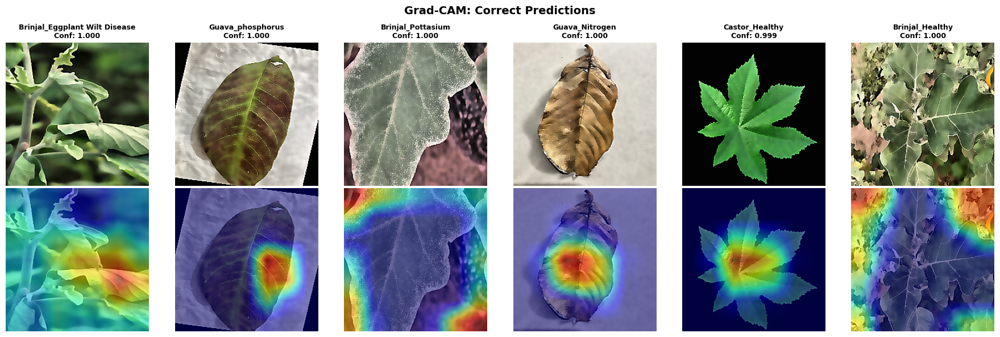

In [5]:
print("\nGenerating Grad-CAM for correct predictions...\n")

sample_correct = np.random.choice(correct_indices, min(6, len(correct_indices)), replace=False)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

for idx, img_idx in enumerate(sample_correct):
    img_array = X_test[img_idx:img_idx+1]
    img = (X_test[img_idx] * 255).astype(np.uint8)

    heatmap = grad_cam.generate(img_array)
    overlaid = grad_cam.overlay_heatmap(img, heatmap, alpha=0.5)

    axes[0, idx].imshow(img)
    axes[0, idx].set_title(f"{class_names[true_labels_idx[img_idx]]}\nConf: {confidence[img_idx]:.3f}", fontweight='bold', fontsize=9)
    axes[0, idx].axis('off')

    axes[1, idx].imshow(overlaid)
    axes[1, idx].axis('off')

plt.suptitle('Grad-CAM: Correct Predictions', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('../results/plots/gradcam_correct_predictions.png', dpi=300, bbox_inches='tight')
print("✓ Saved: gradcam_correct_predictions.png")

### 4. Grad-CAM for Misclassifications


Generating Grad-CAM for misclassifications...

✓ Saved: gradcam_misclassifications.png


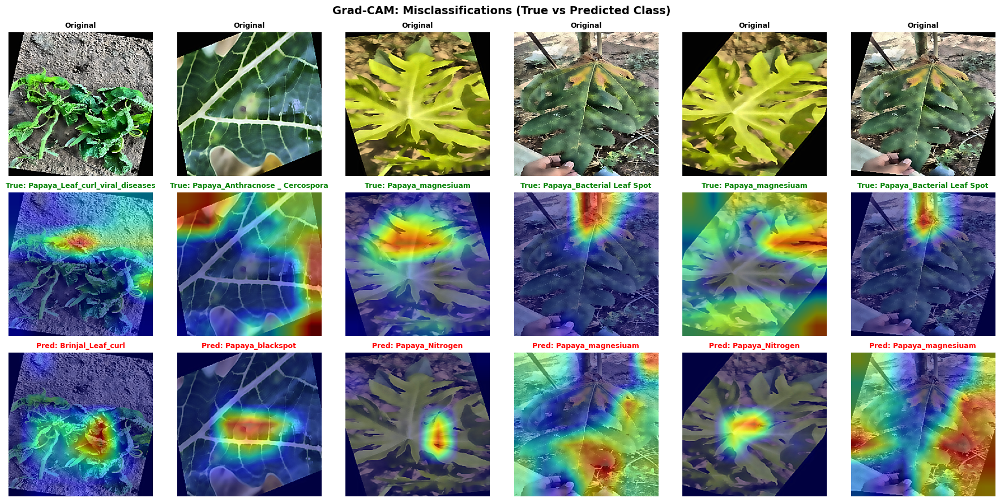

In [6]:
if len(incorrect_indices) > 0:
    print("\nGenerating Grad-CAM for misclassifications...\n")

    sample_incorrect = np.random.choice(incorrect_indices, min(6, len(incorrect_indices)), replace=False)

    fig, axes = plt.subplots(3, 6, figsize=(18, 9))

    for idx, img_idx in enumerate(sample_incorrect):
        img_array = X_test[img_idx:img_idx+1]
        img = (X_test[img_idx] * 255).astype(np.uint8)

        heatmap_true = grad_cam.generate(img_array, pred_index=true_labels_idx[img_idx])
        heatmap_pred = grad_cam.generate(img_array, pred_index=pred_labels_idx[img_idx])

        overlaid_true = grad_cam.overlay_heatmap(img, heatmap_true, alpha=0.5)
        overlaid_pred = grad_cam.overlay_heatmap(img, heatmap_pred, alpha=0.5)

        axes[0, idx].imshow(img)
        axes[0, idx].set_title("Original", fontweight='bold', fontsize=9)
        axes[0, idx].axis('off')

        axes[1, idx].imshow(overlaid_true)
        axes[1, idx].set_title(f"True: {class_names[true_labels_idx[img_idx]]}", fontweight='bold', fontsize=9, color='green')
        axes[1, idx].axis('off')

        axes[2, idx].imshow(overlaid_pred)
        axes[2, idx].set_title(f"Pred: {class_names[pred_labels_idx[img_idx]]}", fontweight='bold', fontsize=9, color='red')
        axes[2, idx].axis('off')

    plt.suptitle('Grad-CAM: Misclassifications (True vs Predicted Class)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('../results/plots/gradcam_misclassifications.png', dpi=300, bbox_inches='tight')
    print("✓ Saved: gradcam_misclassifications.png")
else:
    print("No misclassifications found!")

### 5. Grad-CAM by Class


Generating Grad-CAM for each class...

✓ Saved: gradcam_class_0_brinjal_healthy.png
✓ Saved: gradcam_class_1_brinjal_early_leaf_spot.png
✓ Saved: gradcam_class_2_brinjal_eggplant_wilt_disease.png
✓ Saved: gradcam_class_3_brinjal_leaf_curl.png
✓ Saved: gradcam_class_4_brinjal_little_leaf.png


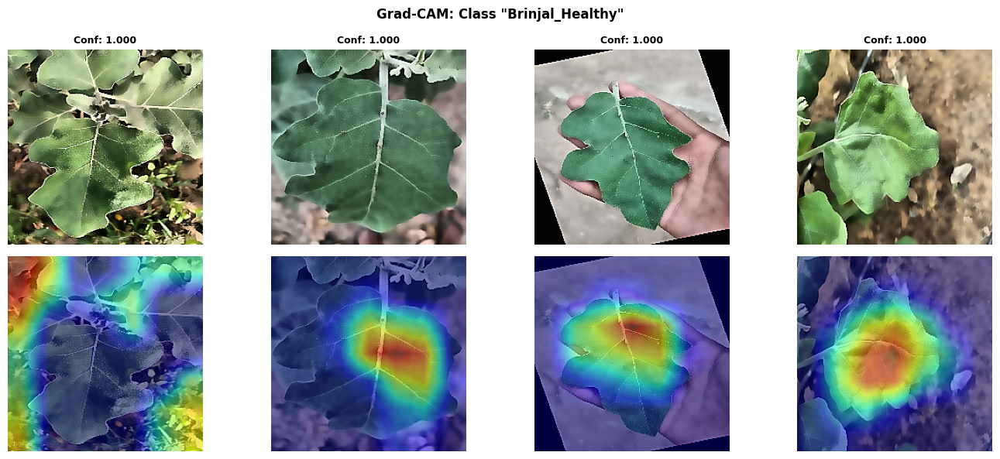

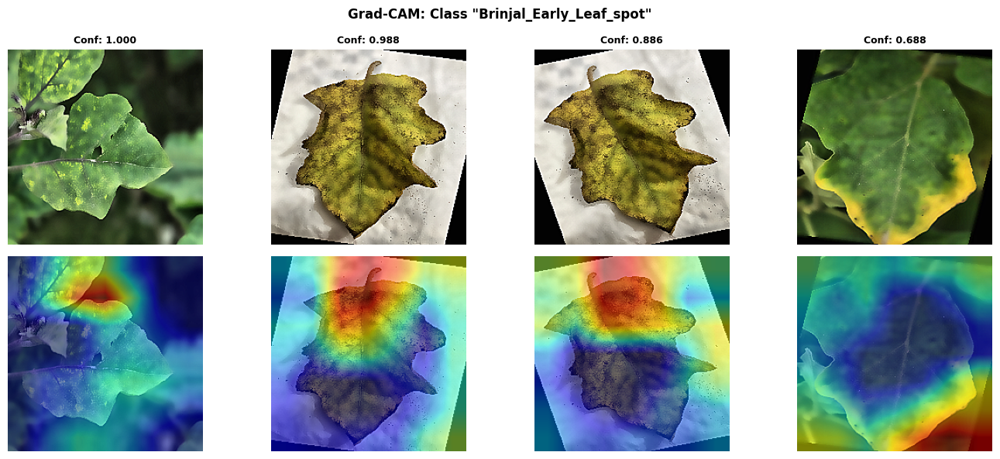

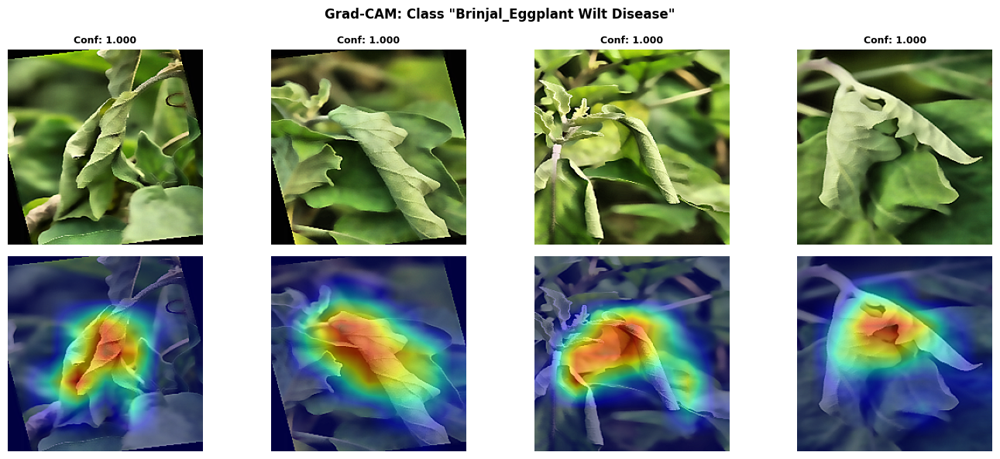

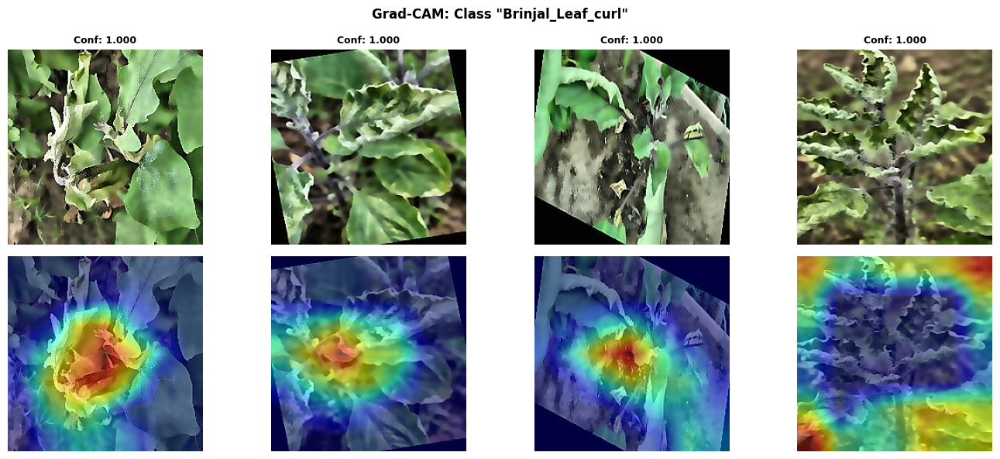

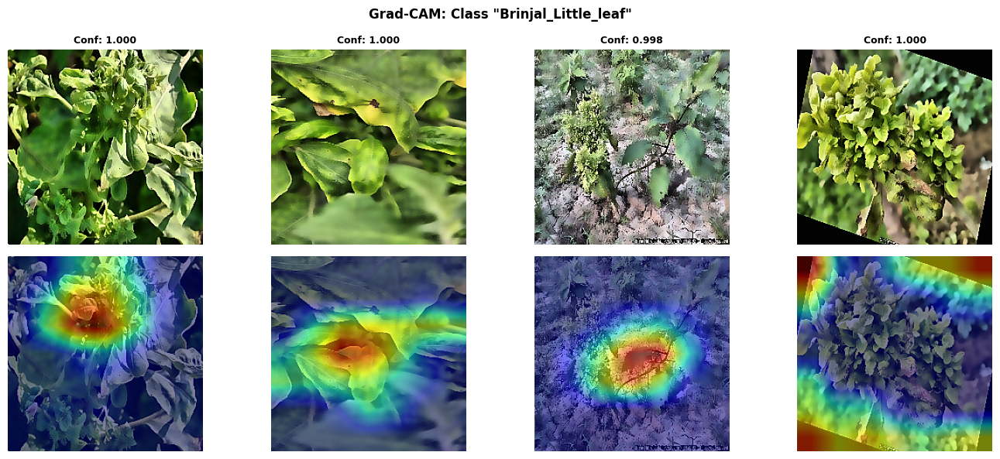

In [7]:
print("\nGenerating Grad-CAM for each class...\n")

for class_idx, class_name in enumerate(class_names[:5]):
    class_correct_mask = (true_labels_idx == class_idx) & correct_mask
    class_indices = np.where(class_correct_mask)[0]

    if len(class_indices) > 0:
        sample_class_idx = np.random.choice(class_indices, min(4, len(class_indices)), replace=False)

        fig, axes = plt.subplots(2, 4, figsize=(14, 6))

        for idx, img_idx in enumerate(sample_class_idx):
            img_array = X_test[img_idx:img_idx+1]
            img = (X_test[img_idx] * 255).astype(np.uint8)

            heatmap = grad_cam.generate(img_array, pred_index=class_idx)
            overlaid = grad_cam.overlay_heatmap(img, heatmap, alpha=0.5)

            axes[0, idx].imshow(img)
            axes[0, idx].set_title(f"Conf: {confidence[img_idx]:.3f}", fontweight='bold', fontsize=9)
            axes[0, idx].axis('off')

            axes[1, idx].imshow(overlaid)
            axes[1, idx].axis('off')

        for idx in range(len(sample_class_idx), 4):
            axes[0, idx].axis('off')
            axes[1, idx].axis('off')

        plt.suptitle(f'Grad-CAM: Class "{class_name}"', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'../results/plots/gradcam_class_{class_idx}_{class_name.replace(" ", "_").lower()}.png', dpi=300, bbox_inches='tight')
        print(f"✓ Saved: gradcam_class_{class_idx}_{class_name.lower().replace(' ', '_')}.png")

### 6. Heatmap Analysis

In [8]:
print("\n" + "="*70)
print("HEATMAP ANALYSIS")
print("="*70 + "\n")

heatmap_stats = []

for img_idx in correct_indices[:100]:
    img_array = X_test[img_idx:img_idx+1]
    heatmap = grad_cam.generate(img_array)

    heatmap_stats.append({
        'mean_activation': heatmap.mean(),
        'max_activation': heatmap.max(),
        'std_activation': heatmap.std(),
        'concentration': (heatmap > heatmap.mean()).sum() / heatmap.size
    })

print("Heatmap Statistics (Correct Predictions):")
print(f"  Mean Activation: {np.mean([s['mean_activation'] for s in heatmap_stats]):.4f}")
print(f"  Max Activation: {np.mean([s['max_activation'] for s in heatmap_stats]):.4f}")
print(f"  Std Activation: {np.mean([s['std_activation'] for s in heatmap_stats]):.4f}")
print(f"  Avg Concentration: {np.mean([s['concentration'] for s in heatmap_stats]):.4f}")


HEATMAP ANALYSIS



Heatmap Statistics (Correct Predictions):
  Mean Activation: 0.1789
  Max Activation: 0.9800
  Std Activation: 0.2637
  Avg Concentration: 0.2955


### 7. Generate Explainability Report

In [9]:
print("\nGenerating explainability report...\n")

explainability_report = {
    'model': best_model_name,
    'method': 'Grad-CAM',
    'interpretation_layer': last_conv_layer.name,
    'summary': {
        'correct_predictions': int(len(correct_indices)),
        'incorrect_predictions': int(len(incorrect_indices)),
        'total_predictions': int(len(X_test)),
        'accuracy': float(len(correct_indices) / len(X_test))
    },
    'heatmap_analysis': {
        'mean_activation': float(np.mean([s['mean_activation'] for s in heatmap_stats])),
        'max_activation': float(np.mean([s['max_activation'] for s in heatmap_stats])),
        'std_activation': float(np.mean([s['std_activation'] for s in heatmap_stats])),
        'avg_concentration': float(np.mean([s['concentration'] for s in heatmap_stats]))
    },
    'insights': [
        'Grad-CAM reveals which image regions contribute to model predictions',
        'High concentration values indicate focused attention on specific features',
        'Comparing true class vs predicted class heatmaps shows misclassification causes',
        'Heatmaps should concentrate on disease/health indicators for reliability'
    ]
}

with open('../results/reports/explainability_report.json', 'w') as f:
    json.dump(explainability_report, f, indent=4)

print("✓ Explainability report saved")
print(json.dumps(explainability_report, indent=2))


Generating explainability report...

✓ Explainability report saved
{
  "model": "ResNet50",
  "method": "Grad-CAM",
  "interpretation_layer": "conv5_block3_3_conv",
  "summary": {
    "correct_predictions": 832,
    "incorrect_predictions": 28,
    "total_predictions": 860,
    "accuracy": 0.9674418604651163
  },
  "heatmap_analysis": {
    "mean_activation": 0.17886528372764587,
    "max_activation": 0.9800000190734863,
    "std_activation": 0.263701468706131,
    "avg_concentration": 0.2955102040816327
  },
  "insights": [
    "Grad-CAM reveals which image regions contribute to model predictions",
    "High concentration values indicate focused attention on specific features",
    "Comparing true class vs predicted class heatmaps shows misclassification causes",
    "Heatmaps should concentrate on disease/health indicators for reliability"
  ]
}


### 8. Create Interpretation Guide

In [10]:
interpretation_guide = """
# Grad-CAM Interpretation Guide

## What is Grad-CAM?
Gradient-weighted Class Activation Mapping (Grad-CAM) produces visual explanations 
for decisions from a large class of Convolutional Neural Networks (CNNs).

## How to Read the Visualizations:

1. **Heatmap Colors**:
   - Red/Warm colors: High model attention (important regions)
   - Blue/Cool colors: Low model attention (less important regions)
   - Green: Medium attention

2. **Correct Predictions**:
   - Should show heatmaps concentrated on disease/health indicators
   - Red regions should align with visual symptoms
   - Indicates reliable decision-making

3. **Misclassifications**:
   - Comparing true vs predicted class heatmaps reveals why model made the error
   - If heatmaps overlap, model confused similar features
   - If heatmaps differ greatly, model attended to wrong regions

## Trust Indicators:

✓ **High Trust**: 
  - Focused heatmaps on disease/symptom regions
  - Heatmap concentrates on relevant areas
  - Consistent across same disease class

⚠️ **Medium Trust**:
  - Heatmaps somewhat diffuse
  - Some attention on irrelevant regions
  - Works but could be improved

✗ **Low Trust**:
  - Uniform heatmaps across entire image
  - Random attention patterns
  - Model likely making random decisions

## Generated Visualizations:

1. **gradcam_correct_predictions.png**: Correctly classified images
2. **gradcam_misclassifications.png**: Misclassified images with true vs predicted class attention
3. **gradcam_class_*.png**: Attention patterns per disease/health class

## Recommendations:

- Use Grad-CAM to validate model reliability before deployment
- If heatmaps look suspicious, gather more training data
- Fine-tune model if attention patterns are unfocused
- Combine with domain expert review for production deployment
"""

with open('../results/reports/gradcam_interpretation_guide.txt', 'w') as f:
    f.write(interpretation_guide)

print("✓ Interpretation guide saved")

✓ Interpretation guide saved


### 9. Summary

In [11]:
print("\n" + "="*70)
print("✓ GRAD-CAM ANALYSIS COMPLETE")
print("="*70)

print(f"\n📊 Analysis Summary:")
print(f"  Model: {best_model_name}")
print(f"  Interpretation Layer: {last_conv_layer}")
print(f"  Correct Predictions Analyzed: {len(correct_indices)}")
print(f"  Incorrect Predictions Analyzed: {len(incorrect_indices)}")

print(f"\n📈 Heatmap Characteristics:")
print(f"  Mean Activation: {np.mean([s['mean_activation'] for s in heatmap_stats]):.4f}")
print(f"  Max Activation: {np.mean([s['max_activation'] for s in heatmap_stats]):.4f}")
print(f"  Avg Concentration: {np.mean([s['concentration'] for s in heatmap_stats]):.4f}")

print(f"\n💾 Files Generated:")
print(f"  - gradcam_correct_predictions.png")
print(f"  - gradcam_misclassifications.png")
print(f"  - gradcam_class_*.png (per-class analysis)")
print(f"  - explainability_report.json")
print(f"  - gradcam_interpretation_guide.txt")

print(f"\n✓ All notebooks completed successfully!")
print(f"  Review explainability visualizations in: ../results/plots/")
print(f"  Read interpretation guide: ../results/reports/gradcam_interpretation_guide.txt")


✓ GRAD-CAM ANALYSIS COMPLETE

📊 Analysis Summary:
  Model: ResNet50
  Interpretation Layer: <keras.src.layers.convolutional.conv2d.Conv2D object at 0x0000012C31DC3E80>
  Correct Predictions Analyzed: 832
  Incorrect Predictions Analyzed: 28

📈 Heatmap Characteristics:
  Mean Activation: 0.1789
  Max Activation: 0.9800
  Avg Concentration: 0.2955

💾 Files Generated:
  - gradcam_correct_predictions.png
  - gradcam_misclassifications.png
  - gradcam_class_*.png (per-class analysis)
  - explainability_report.json
  - gradcam_interpretation_guide.txt

✓ All notebooks completed successfully!
  Review explainability visualizations in: ../results/plots/
  Read interpretation guide: ../results/reports/gradcam_interpretation_guide.txt
